# XGBoost

Classificação de churn com o XGBoost (*eXtreme Gradient Boosting*), avaliada com a validação cruzada estratificada de 10 folds comum a todos os algoritmos (`data/processed/folds.csv`).

**Pergunta central**: quanta complexidade o problema pede? Comparamos duas configurações que variam só a profundidade das árvores (**opção A**: `max_depth` 3 × 6) com uma grade de profundidade × taxa de aprendizado (**opção B**: 4 × 3 = 12 configurações), nas bases com e sem `inativo`. A opção A está contida na grade, e a comparação mostra se a busca mais ampla acrescenta algo além da variação entre folds.

## Como o XGBoost funciona

### Árvores de decisão

Uma árvore de decisão divide os clientes por perguntas sobre um atributo de cada vez ("`reclamacao` ≤ 0,5?", "`qtd_ligacoes` ≤ 3,2?"), até chegar às **folhas**. No XGBoost, cada folha não guarda uma classe, e sim um **valor numérico** (peso) que é somado à previsão. A profundidade máxima da árvore (`max_depth`) limita quantas perguntas encadeadas uma regra pode ter, ou seja, quantos atributos podem interagir numa mesma regra.

### Boosting: árvores somadas em sequência

O XGBoost é um ***gradient boosting*** de árvores: em vez de uma árvore grande, constrói **muitas árvores pequenas em sequência**, e cada nova árvore corrige os erros das anteriores. A previsão de um cliente é a soma das árvores, na escala do log-odds (logit):

$$F_M(x) = F_0 + \eta \sum_{m=1}^{M} f_m(x), \qquad \hat p(x) = \sigma(F_M(x)) = \frac{1}{1 + e^{-F_M(x)}}$$

- $F_0 = \log\frac{\bar p}{1 - \bar p}$ é o ponto de partida: o log-odds da proporção de churn no treino (ponderada pelos pesos de classe).
- $f_m$ é a árvore da rodada $m$, $M$ é o número de árvores (`n_estimators`) e $\eta$ é a **taxa de aprendizado** (`learning_rate`). Ela encolhe a contribuição de cada árvore, para que nenhuma sozinha domine o modelo.

### O que cada árvore aprende: gradiente e hessiana

A perda é a entropia cruzada (log loss), $\ell(y, F) = -[y \log p + (1 - y)\log(1 - p)]$ com $p = \sigma(F)$. Na rodada $m$, o XGBoost aproxima a perda em torno da previsão atual por uma **expansão de Taylor de 2ª ordem**, usando para cada cliente $i$:

$$g_i = \frac{\partial \ell}{\partial F} = p_i - y_i \quad \text{(gradiente)}, \qquad h_i = \frac{\partial^2 \ell}{\partial F^2} = p_i (1 - p_i) \quad \text{(hessiana)}.$$

O gradiente diz em que direção e quanto a previsão do cliente está errada. A hessiana diz quão "certa" já é a previsão: é pequena quando $p_i$ está perto de 0 ou 1. Usar a 2ª derivada (método de Newton) é a principal diferença em relação ao *gradient boosting* clássico, que usa só o gradiente.

### Peso ótimo de cada folha

Somando $G = \sum g_i$ e $H = \sum h_i$ sobre os clientes que caem numa folha, a perda aproximada com regularização L2 ($\lambda$) é minimizada pelo peso

$$w^* = -\frac{G}{H + \lambda},$$

e a melhor perda alcançável por aquela folha é $-\frac{1}{2}\frac{G^2}{H + \lambda}$.

### Ganho de uma divisão

Para decidir se vale dividir um nó em esquerda (L) e direita (R), o XGBoost calcula o **ganho**: a redução da perda com a divisão, menos uma penalidade $\gamma$ por folha nova:

$$\text{ganho} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\right] - \gamma.$$

A árvore é construída de forma **gulosa**: em cada nó, testa todos os atributos e cortes candidatos, escolhe o de maior ganho e só divide se o ganho for positivo, a profundidade não tiver chegado a `max_depth` e cada filho tiver hessiana total de pelo menos `min_child_weight`.

### Detalhes da implementação usada

- **`tree_method='hist'`**: em vez de testar todos os valores distintos de cada atributo, agrupa os valores em faixas (histograma, até 256) e testa só as fronteiras. É mais rápido, com efeito desprezível numa base deste tamanho.
- **`scale_pos_weight`**: multiplica o $g_i$ e o $h_i$ dos clientes churn. Com o valor nº de não churn ÷ nº de churn, as duas classes pesam o mesmo na soma de $G$ e $H$, o equivalente ao critério "balanced" dos outros algoritmos.
- **Importância por `gain`**: para cada atributo, a média do ganho de todas as divisões que o usam. Mede quanto o atributo reduziu a perda quando foi escolhido.

### Pseudocódigo

```
XGBoost(treino {(x_i, y_i)}, M, η, max_depth, λ, γ, min_child_weight, spw):
    # pesos de classe: churn pesa spw, não churn pesa 1
    v_i ← spw se y_i = 1, senão 1
    F_0 ← log( Σ v_i y_i / Σ v_i (1 − y_i) )          # log-odds ponderado
    F(x_i) ← F_0 para todo i

    para m = 1 até M:
        p_i ← σ(F(x_i))
        g_i ← v_i · (p_i − y_i)                       # gradiente
        h_i ← v_i · p_i · (1 − p_i)                   # hessiana
        f_m ← ConstruirÁrvore(todos os i, profundidade = 0)
        F(x_i) ← F(x_i) + η · f_m(x_i)                # encolhimento pela taxa

    devolver F

ConstruirÁrvore(conjunto I, profundidade):
    G ← Σ_{i∈I} g_i ;  H ← Σ_{i∈I} h_i
    se profundidade = max_depth:
        devolver Folha(w = −G / (H + λ))
    melhor ← (ganho = 0, nenhum corte)
    para cada atributo j:
        para cada corte c nas fronteiras do histograma de j:
            I_L ← {i ∈ I : x_ij ≤ c} ;  I_R ← I − I_L
            se Σ_{I_L} h < min_child_weight ou Σ_{I_R} h < min_child_weight: pular
            ganho ← ½ [ G_L²/(H_L+λ) + G_R²/(H_R+λ) − G²/(H+λ) ] − γ
            se ganho > melhor.ganho: melhor ← (ganho, j, c)
    se nenhum corte com ganho > 0:
        devolver Folha(w = −G / (H + λ))
    devolver Nó(j, c,
                esquerda = ConstruirÁrvore(I_L, profundidade + 1),
                direita  = ConstruirÁrvore(I_R, profundidade + 1))

Prever(x):
    devolver σ(F(x))      # probabilidade de churn; churn se ≥ 0,5
```

## Por que o XGBoost neste problema

- **Não linearidades e interações**: a análise exploratória mostrou efeitos que dependem de combinações de atributos, como a reclamação somada à taxa de falha alta (H4), o limiar "uso = 0" (52% de churn entre os 107 clientes sem uso) e o churn quase nulo nos grupos de idade extremos. Uma árvore representa isso diretamente com cortes encadeados, sem que seja preciso criar atributos (não criamos taxa de falha nem `sem_uso`).
- **Estado da arte em dados tabulares**: o *gradient boosting* de árvores costuma ser o modelo mais forte em bases tabulares de tamanho médio, como esta.
- **Indiferente à escala e robusto a correlações**: os cortes só usam a ordem dos valores, e atributos redundantes (segundos × ligações) apenas dividem os cortes entre si, sem quebrar nenhuma suposição do modelo (ao contrário do Naive Bayes).
- **Regularização embutida**: $\lambda$, $\gamma$, `min_child_weight` e a taxa de aprendizado controlam o sobreajuste, importante com 446 churns e ruído de rótulo (14 combinações conflitantes).
- **Interpretação**: a importância por `gain` permite conferir H1 (nenhum atributo isolado decisivo?), H2 (peso da reclamação) e H6 (peso do uso) com todos os atributos juntos.

## Pré-processamento necessário para o XGBoost

| etapa | situação | por quê |
|---|---|---|
| padronização | **não aplicada** | os cortes das árvores dependem só da ordem dos valores; mudar a escala não muda nenhuma divisão |
| `log1p` nos atributos de uso | já está na base; **sem efeito** | o log preserva a ordem, então as divisões possíveis são as mesmas. A base é usada como está, para que todos os algoritmos recebam os mesmos dados |
| **idade numérica (sem one-hot)** | reconstruída neste notebook (`idade_numerica`, de `comum.py`) | a idade é ordinal com 5 valores, e poucos cortes ("idade ≤ 25", "idade ≤ 45") separam as faixas, inclusive os extremos com churn quase nulo. Com o one-hot, a mesma informação ficaria espalhada em 5 colunas, e a importância da idade dividida entre elas |
| binários (`reclamacao`, `plano_contratual`, `inativo`) | usados como estão (0/1) | um único corte em 0,5 os separa |
| desbalanceamento | `scale_pos_weight` = não churn ÷ churn **no treino de cada fold** (~5,4) | sem ele, os 84% de não churn dominam o gradiente e o recall cai |

A idade numérica é uma transformação linha a linha, sem vazamento. O `scale_pos_weight` é calculado dentro do fold, só com o `y` do treino.

## Parâmetros

**Variados**:

| parâmetro | valores | papel e justificativa |
|---|---|---|
| `max_depth` | 2, 3, 4, 6 | profundidade de cada árvore, isto é, até quantos atributos interagem numa regra. Com 2, só interações de pares (como falhas × reclamação, H4); com 6 (o padrão), interações de até 6 atributos, mais risco de sobreajuste |
| `learning_rate` (η) | 0,05; 0,1; 0,3 | encolhimento de cada árvore. Com η pequeno, cada árvore corrige pouco, e as 300 árvores podem não bastar (subajuste); com η grande (0,3, o padrão), o modelo se ajusta rápido, mas pode sobreajustar |

- **Opção A**: `d3_lr0.1` e `d6_lr0.1` (só muda a profundidade).
- **Opção B**: a grade completa 4 × 3 (12 configurações), que contém as duas da opção A.

**Fixos**:

| parâmetro | valor | justificativa |
|---|---|---|
| `n_estimators` (M) | 300 | orçamento igual de árvores para todas as configurações, sem parada antecipada (como na MLP) |
| `objective` | `binary:logistic` | perda log loss e saída em probabilidade |
| `scale_pos_weight` | não churn ÷ churn no treino do fold | pesos de classe "balanced" |
| `reg_lambda` (λ) | 1 (padrão) | penalidade L2 no peso das folhas ($w^* = -G/(H+\lambda)$) |
| `gamma` (γ) | 0 (padrão) | sem ganho mínimo extra: divide sempre que o ganho for positivo |
| `min_child_weight` | 1 (padrão) | hessiana mínima por folha |
| `subsample`, `colsample_bytree` | 1 (padrão) | todas as linhas e colunas em cada árvore, sem subamostragem |
| `tree_method` | `hist` | cortes por histograma |
| `random_state` | `SEMENTE` (42) | reprodutibilidade |

Total: 12 configurações × 2 bases = **24 rodadas de 10 folds**, mais 2 rodadas da configuração escolhida **sem `scale_pos_weight`** (seção "Efeito do desbalanceamento").

## Configuração

In [1]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from xgboost import XGBClassifier

from comum import (METRICAS, N_CHURN, N_LINHAS, RESULTS_DIR, SEMENTE, avaliar,
                   carregar_base, carregar_folds, idade_numerica, nome_base,
                   registrar_escolhida, salvar_resultados, salvar_tabela,
                   tabela_desbalanceamento)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

N_ARVORES = 300
PROFUNDIDADES = [2, 3, 4, 6]
TAXAS = [0.05, 0.1, 0.3]
OPCAO_A = ['d3_lr0.1', 'd6_lr0.1']


def nome_config(prof, taxa):
    return f'd{prof}_lr{taxa}'


GRADE = {nome_config(p, t): (p, t) for p, t in product(PROFUNDIDADES, TAXAS)}
assert set(OPCAO_A) <= set(GRADE)
print(f'{len(GRADE)} configurações × 2 bases = {len(GRADE) * 2} rodadas')

12 configurações × 2 bases = 24 rodadas


In [2]:
def criar_xgb(prof, taxa, usar_spw=True):
    # devolve a função que o avaliar chama em cada fold
    # usar_spw=False só na seção do desbalanceamento
    def criar(y_treino):
        spw = (y_treino == 0).sum() / (y_treino == 1).sum() if usar_spw else 1.0  # só com o y do treino
        return XGBClassifier(
            n_estimators=N_ARVORES,
            max_depth=prof,
            learning_rate=taxa,
            objective='binary:logistic',
            scale_pos_weight=spw,
            reg_lambda=1.0,
            gamma=0.0,
            min_child_weight=1,
            subsample=1.0,
            colsample_bytree=1.0,
            tree_method='hist',
            random_state=SEMENTE,
            n_jobs=-1,
        )
    return criar

## Dados e folds

As duas bases recebem a idade numérica no lugar das 5 colunas one-hot. Têm as mesmas linhas e o mesmo `churn`, então usam os mesmos folds.

In [3]:
bases = {}
for com_status in [True, False]:
    X, y = carregar_base(com_status)
    bases[com_status] = (idade_numerica(X), y)
y = bases[True][1]
assert np.array_equal(y, bases[False][1])
folds = carregar_folds(y)

for com_status, (X, _) in bases.items():
    print(f'{nome_base(com_status)}: {X.shape[1]} atributos -> {list(X.columns)}')

com-status: 12 atributos -> ['falhas_ligacao', 'meses_assinatura', 'faixa_cobranca', 'segundos_uso', 'qtd_ligacoes', 'qtd_sms', 'numeros_distintos', 'valor_cliente', 'reclamacao', 'plano_contratual', 'inativo', 'idade']
sem-status: 11 atributos -> ['falhas_ligacao', 'meses_assinatura', 'faixa_cobranca', 'segundos_uso', 'qtd_ligacoes', 'qtd_sms', 'numeros_distintos', 'valor_cliente', 'reclamacao', 'plano_contratual', 'idade']


## Execução da grade

In [4]:
linhas, resultados = [], {}
for com_status, (X, y) in bases.items():
    base = nome_base(com_status)
    for config, (prof, taxa) in GRADE.items():
        r = avaliar(criar_xgb(prof, taxa), X, y, folds)
        assert r['matriz'].sum() == N_LINHAS
        assert r['matriz'][1].sum() == N_CHURN

        resultados[(config, base)] = r
        linhas.append(r['por_fold'].reset_index().assign(
            base=base, config=config, max_depth=prof, learning_rate=taxa,
            opcao_a=config in OPCAO_A))
    print(f'{base}: concluída')

grade = pd.concat(linhas, ignore_index=True)
assert len(grade) == len(GRADE) * 2 * 10
grade.to_csv(RESULTS_DIR / 'xgb-grade-metricas.csv', index=False)

com-status: concluída
sem-status: concluída


## Resumo por configuração

Média ± desvio nos 10 folds, ordenado por PR-AUC. A coluna `opção A` marca as duas configurações da opção A.

In [5]:
CHAVES = ['base', 'config', 'max_depth', 'learning_rate', 'opcao_a']
resumo = grade.groupby(CHAVES)[METRICAS].agg(['mean', 'std'])
resumo.columns = [f'{m}_{"media" if e == "mean" else "desvio"}' for m, e in resumo.columns]
resumo = resumo.reset_index()
resumo.to_csv(RESULTS_DIR / 'xgb-grade-resumo.csv', index=False)


def formatar(res):
    t = res[['config']].copy()
    t['opção A'] = res['opcao_a'].map({True: '✔', False: ''})
    for m in METRICAS:
        t[m] = res[f'{m}_media'].map('{:.3f}'.format) + ' ± ' + res[f'{m}_desvio'].map('{:.3f}'.format)
    return t.reset_index(drop=True)


for base in ['sem-status', 'com-status']:
    print(f'\n=== base {base} (ordenada por PR-AUC) ===')
    tab = formatar(resumo[resumo['base'] == base].sort_values('pr_auc_media', ascending=False))
    display(tab)
    salvar_tabela(tab, f'xgb-tab-resumo-{base}')


=== base sem-status (ordenada por PR-AUC) ===


,config,opção A,recall,especificidade,f1_macro,log_loss,pr_auc
0,d4_lr0.1,,0.912 ± 0.063,0.965 ± 0.013,0.922 ± 0.032,0.117 ± 0.039,0.940 ± 0.034
1,d3_lr0.3,,0.899 ± 0.050,0.970 ± 0.014,0.925 ± 0.029,0.117 ± 0.053,0.940 ± 0.039
2,d6_lr0.1,✔,0.883 ± 0.059,0.973 ± 0.014,0.924 ± 0.029,0.118 ± 0.058,0.938 ± 0.042
3,d4_lr0.3,,0.861 ± 0.048,0.973 ± 0.013,0.916 ± 0.027,0.130 ± 0.062,0.937 ± 0.038
4,d6_lr0.05,,0.894 ± 0.060,0.967 ± 0.013,0.918 ± 0.029,0.119 ± 0.043,0.937 ± 0.040
5,d2_lr0.3,,0.914 ± 0.059,0.958 ± 0.012,0.913 ± 0.026,0.129 ± 0.037,0.932 ± 0.037
6,d3_lr0.1,✔,0.928 ± 0.052,0.950 ± 0.010,0.906 ± 0.023,0.136 ± 0.030,0.931 ± 0.037
7,d6_lr0.3,,0.850 ± 0.058,0.974 ± 0.012,0.913 ± 0.029,0.146 ± 0.075,0.931 ± 0.040
8,d4_lr0.05,,0.921 ± 0.062,0.947 ± 0.011,0.900 ± 0.027,0.142 ± 0.026,0.927 ± 0.037
9,d3_lr0.05,,0.928 ± 0.044,0.928 ± 0.011,0.878 ± 0.016,0.181 ± 0.022,0.903 ± 0.043



=== base com-status (ordenada por PR-AUC) ===


,config,opção A,recall,especificidade,f1_macro,log_loss,pr_auc
0,d6_lr0.1,✔,0.894 ± 0.061,0.976 ± 0.011,0.931 ± 0.028,0.103 ± 0.055,0.955 ± 0.033
1,d6_lr0.05,,0.915 ± 0.053,0.975 ± 0.010,0.935 ± 0.024,0.100 ± 0.041,0.955 ± 0.033
2,d4_lr0.1,,0.906 ± 0.062,0.971 ± 0.012,0.927 ± 0.031,0.104 ± 0.042,0.951 ± 0.033
3,d3_lr0.3,,0.899 ± 0.053,0.974 ± 0.012,0.930 ± 0.028,0.109 ± 0.053,0.949 ± 0.034
4,d4_lr0.3,,0.876 ± 0.053,0.976 ± 0.012,0.926 ± 0.027,0.118 ± 0.065,0.949 ± 0.035
5,d6_lr0.3,,0.870 ± 0.052,0.978 ± 0.012,0.925 ± 0.027,0.134 ± 0.073,0.945 ± 0.035
6,d4_lr0.05,,0.926 ± 0.057,0.954 ± 0.012,0.910 ± 0.028,0.126 ± 0.029,0.943 ± 0.038
7,d3_lr0.1,✔,0.928 ± 0.045,0.958 ± 0.012,0.917 ± 0.025,0.124 ± 0.031,0.942 ± 0.034
8,d2_lr0.3,,0.923 ± 0.046,0.963 ± 0.015,0.922 ± 0.031,0.119 ± 0.041,0.940 ± 0.038
9,d3_lr0.05,,0.930 ± 0.043,0.931 ± 0.014,0.883 ± 0.022,0.163 ± 0.020,0.922 ± 0.037


### Profundidade × taxa de aprendizado

PR-AUC e recall médios de cada célula da grade. As células da opção A são `max_depth` 3 e 6 com taxa 0,1.

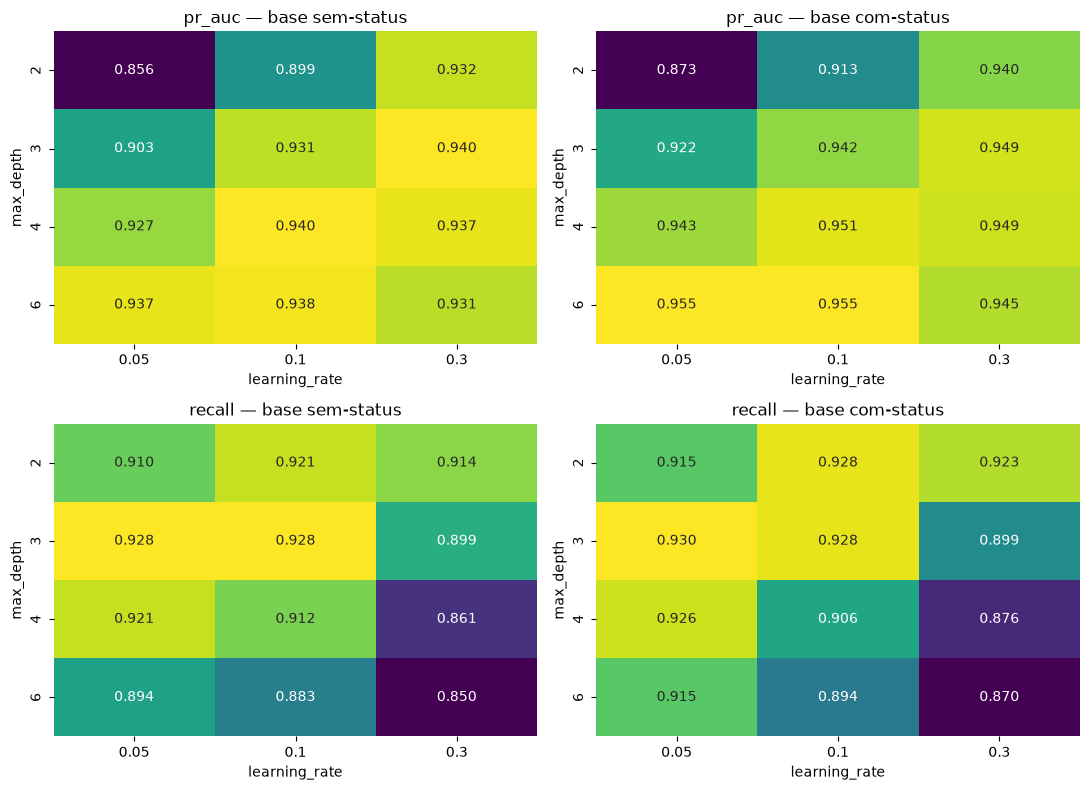

In [6]:
fig, eixos = plt.subplots(2, 2, figsize=(11, 8))
for j, base in enumerate(['sem-status', 'com-status']):
    for i, metrica in enumerate(['pr_auc', 'recall']):
        mapa = (resumo[resumo['base'] == base]
                .pivot(index='max_depth', columns='learning_rate', values=f'{metrica}_media'))
        sns.heatmap(mapa, annot=True, fmt='.3f', cmap='viridis', ax=eixos[i, j], cbar=False)
        eixos[i, j].set_title(f'{metrica} — base {base}')
        eixos[i, j].set_xlabel('learning_rate')
        eixos[i, j].set_ylabel('max_depth')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'xgb-grade-heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## Opção A × opção B

A melhor configuração da grade (opção B) é escolhida pela maior PR-AUC média na **base sem `inativo`**, que não tem a suspeita de vazamento. A PR-AUC independe do limiar e não premia um modelo que chama todos de churn.

Ela é comparada **fold a fold** com cada configuração da opção A (os folds são os mesmos), na diferença B − A. Se a diferença média for menor que o seu desvio, a busca mais ampla não ganhou nada além da variação entre folds.

**Parcimônia**: entre as configurações cuja PR-AUC fica a menos de um desvio da melhor, a escolhida é a mais simples (menor `max_depth` e, empatando, maior `learning_rate`, ou seja, o modelo com menos ajuste).

In [7]:
ref = resumo[resumo['base'] == 'sem-status']
melhor_b = ref.sort_values('pr_auc_media', ascending=False).iloc[0]

limite = melhor_b['pr_auc_media'] - melhor_b['pr_auc_desvio']
candidatas = ref[ref['pr_auc_media'] >= limite]
escolhida = candidatas.sort_values(['max_depth', 'learning_rate'], ascending=[True, False]).iloc[0]

print(f'melhor da grade (B): {melhor_b["config"]} '
      f'(PR-AUC {melhor_b["pr_auc_media"]:.3f} ± {melhor_b["pr_auc_desvio"]:.3f})')
print(f'configurações a menos de um desvio da melhor: {list(candidatas["config"])}')
print(f'escolhida pela parcimônia: {escolhida["config"]}')

linhas_cmp = []
for base in ['sem-status', 'com-status']:
    b = grade[(grade['base'] == base) & (grade['config'] == melhor_b['config'])].set_index('fold')
    for config_a in OPCAO_A:
        a = grade[(grade['base'] == base) & (grade['config'] == config_a)].set_index('fold')
        linha = {'base': base, 'comparação': f'{melhor_b["config"]} (B) − {config_a} (A)'}
        for m in METRICAS:
            dif = b[m] - a[m]
            linha[m] = f'{dif.mean():+.3f} ± {dif.std():.3f}'
        linha['folds com PR-AUC maior (B)'] = int((b['pr_auc'] > a['pr_auc']).sum())
        linhas_cmp.append(linha)
tab = pd.DataFrame(linhas_cmp)
salvar_tabela(tab, 'xgb-tab-opcaoA-x-opcaoB')
tab

melhor da grade (B): d4_lr0.1 (PR-AUC 0.940 ± 0.034)
configurações a menos de um desvio da melhor: ['d2_lr0.3', 'd3_lr0.1', 'd3_lr0.3', 'd4_lr0.05', 'd4_lr0.1', 'd4_lr0.3', 'd6_lr0.05', 'd6_lr0.1', 'd6_lr0.3']
escolhida pela parcimônia: d2_lr0.3


,base,comparação,recall,especificidade,f1_macro,log_loss,pr_auc,folds com PR-AUC maior (B)
0,sem-status,d4_lr0.1 (B) − d3_lr0.1 (A),-0.016 ± 0.026,+0.016 ± 0.010,+0.016 ± 0.017,-0.019 ± 0.012,+0.008 ± 0.006,10
1,sem-status,d4_lr0.1 (B) − d6_lr0.1 (A),+0.029 ± 0.026,-0.008 ± 0.006,-0.002 ± 0.009,-0.001 ± 0.022,+0.002 ± 0.011,5
2,com-status,d4_lr0.1 (B) − d3_lr0.1 (A),-0.023 ± 0.035,+0.012 ± 0.009,+0.010 ± 0.017,-0.019 ± 0.015,+0.010 ± 0.010,8
3,com-status,d4_lr0.1 (B) − d6_lr0.1 (A),+0.011 ± 0.028,-0.005 ± 0.010,-0.004 ± 0.019,+0.001 ± 0.016,-0.004 ± 0.006,3


## Configurações finais

As duas da opção A e a melhor da grade (sem repetição, caso a melhor já seja uma da opção A), nas duas bases. Elas vão para o notebook de comparação via `salvar_resultados`.

In [8]:
FINAIS = list(dict.fromkeys(OPCAO_A + [melhor_b['config'], escolhida['config']]))
for config in FINAIS:
    for com_status in [True, False]:
        salvar_resultados(resultados[(config, nome_base(com_status))], 'xgb', config, com_status)
print('salvas:', FINAIS)
registrar_escolhida('xgb', escolhida['config'])

salvas: ['d3_lr0.1', 'd6_lr0.1', 'd4_lr0.1', 'd2_lr0.3']


### Matrizes de confusão

Somadas nos 10 folds.

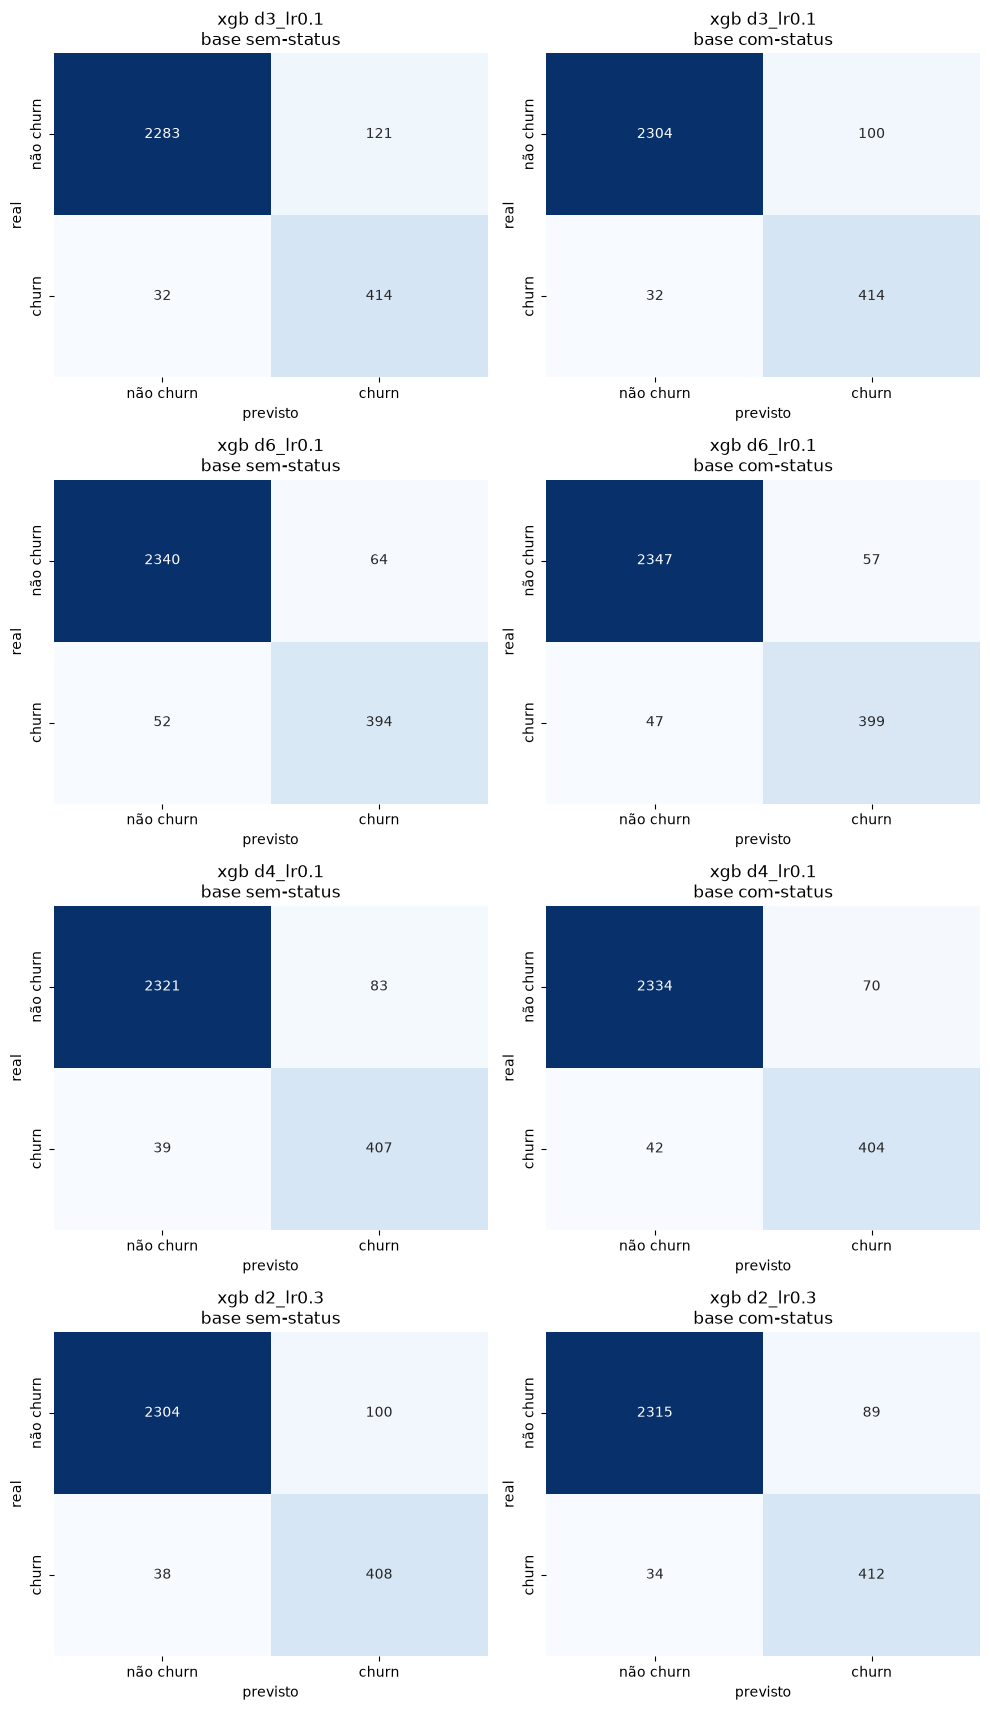

In [9]:
fig, eixos = plt.subplots(len(FINAIS), 2, figsize=(10, 4.3 * len(FINAIS)), squeeze=False)
for i, config in enumerate(FINAIS):
    for j, base in enumerate(['sem-status', 'com-status']):
        ax = eixos[i, j]
        sns.heatmap(resultados[(config, base)]['matriz'], annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=['não churn', 'churn'], yticklabels=['não churn', 'churn'], ax=ax)
        ax.set_title(f'xgb {config}\nbase {base}')
        ax.set_xlabel('previsto')
        ax.set_ylabel('real')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'xgb-matrizes-confusao.png', dpi=150, bbox_inches='tight')
plt.show()

### Comparação com as regras de referência e efeito do `inativo`

In [10]:
tabela = [
    {'modelo': 'regra: reclamou → churn', 'base': '—', 'recall': 0.426, 'especificidade': 0.983},
    {'modelo': 'regra: inativo → churn', 'base': '—', 'recall': 0.729, 'especificidade': 0.851},
]
for config in FINAIS:
    for base in ['sem-status', 'com-status']:
        lin = resumo[(resumo['config'] == config) & (resumo['base'] == base)].iloc[0]
        tabela.append({'modelo': f'xgb {config}', 'base': base,
                       **{m: round(lin[f'{m}_media'], 3) for m in METRICAS}})
tab = pd.DataFrame(tabela)
display(tab)
salvar_tabela(tab, 'xgb-tab-referencia')

efeito = []
for config in FINAIS:
    com = resumo[(resumo['config'] == config) & (resumo['base'] == 'com-status')].iloc[0]
    sem = resumo[(resumo['config'] == config) & (resumo['base'] == 'sem-status')].iloc[0]
    efeito.append({'config': config, **{f'dif {m} (com − sem)': round(com[f'{m}_media'] - sem[f'{m}_media'], 3)
                                        for m in METRICAS}})
tab = pd.DataFrame(efeito)
display(tab)
salvar_tabela(tab, 'xgb-tab-efeito-inativo')

,modelo,base,recall,especificidade,f1_macro,log_loss,pr_auc
0,regra: reclamou → churn,—,0.426,0.983,NaN,NaN,NaN
1,regra: inativo → churn,—,0.729,0.851,NaN,NaN,NaN
2,xgb d3_lr0.1,sem-status,0.928,0.950,0.906,0.136,0.931
3,xgb d3_lr0.1,com-status,0.928,0.958,0.917,0.124,0.942
4,xgb d6_lr0.1,sem-status,0.883,0.973,0.924,0.118,0.938
5,xgb d6_lr0.1,com-status,0.894,0.976,0.931,0.103,0.955
6,xgb d4_lr0.1,sem-status,0.912,0.965,0.922,0.117,0.940
7,xgb d4_lr0.1,com-status,0.906,0.971,0.927,0.104,0.951
8,xgb d2_lr0.3,sem-status,0.914,0.958,0.913,0.129,0.932
9,xgb d2_lr0.3,com-status,0.923,0.963,0.922,0.119,0.940


,config,dif recall (com − sem),dif especificidade (com − sem),dif f1_macro (com − sem),dif log_loss (com − sem),dif pr_auc (com − sem)
0,d3_lr0.1,0.000,0.009,0.012,-0.013,0.010
1,d6_lr0.1,0.011,0.003,0.008,-0.015,0.017
2,d4_lr0.1,-0.007,0.005,0.005,-0.013,0.011
3,d2_lr0.3,0.009,0.005,0.009,-0.010,0.008


WindowsPath('C:/7-periodo/mineracao-dados/trabalho-final/data/results/modelagem/xgb-tab-efeito-inativo.png')

## Importância dos atributos (`gain`)

Ganho médio das divisões que usam cada atributo, na configuração escolhida, calculado em cada um dos 10 modelos (um por fold) e resumido em média ± desvio. Para comparar as bases, a importância é normalizada para somar 1 em cada modelo. Atributos nunca usados em um corte recebem 0.

Leitura para as hipóteses: **H1** (há um atributo isolado decisivo?) se vê na concentração da importância; **H2** na posição de `reclamacao`; **H6** na dos atributos de uso (`qtd_ligacoes`, `segundos_uso`, `qtd_sms`, `numeros_distintos`, `valor_cliente`).

base,com-status,sem-status
atributo,,
reclamacao,0.232,0.415
valor_cliente,0.066,0.180
qtd_ligacoes,0.030,0.068
segundos_uso,0.041,0.066
faixa_cobranca,0.013,0.061
meses_assinatura,0.042,0.056
idade,0.030,0.047
falhas_ligacao,0.021,0.036
numeros_distintos,0.021,0.035


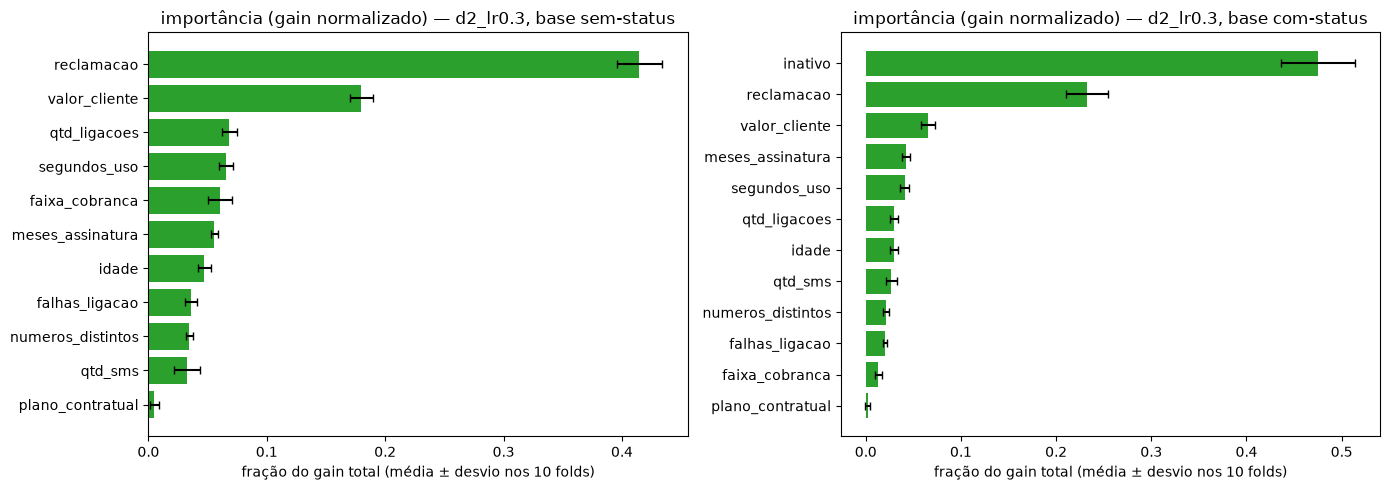

In [11]:
linhas_imp = []
for base in ['sem-status', 'com-status']:
    colunas = list(bases[base == 'com-status'][0].columns)
    for k, modelo in enumerate(resultados[(escolhida['config'], base)]['modelos']):
        ganho = pd.Series(modelo.get_booster().get_score(importance_type='gain')).reindex(colunas, fill_value=0.0)
        ganho = ganho / ganho.sum()
        linhas_imp += [{'base': base, 'fold': k, 'atributo': a, 'gain': g} for a, g in ganho.items()]

importancia = pd.DataFrame(linhas_imp)
importancia.to_csv(RESULTS_DIR / 'xgb-importancia.csv', index=False)

resumo_imp = (importancia.groupby(['base', 'atributo'])['gain'].agg(['mean', 'std'])
              .rename(columns={'mean': 'media', 'std': 'desvio'}).reset_index())
tab = (resumo_imp.pivot(index='atributo', columns='base', values='media')
       .sort_values('sem-status', ascending=False).round(3))
display(tab)
salvar_tabela(tab, 'xgb-tab-importancia')

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for ax, base in zip(eixos, ['sem-status', 'com-status']):
    sub = resumo_imp[resumo_imp['base'] == base].sort_values('media')
    ax.barh(sub['atributo'], sub['media'], xerr=sub['desvio'], color='tab:green', capsize=3)
    ax.set_title(f'importância (gain normalizado) — {escolhida["config"]}, base {base}')
    ax.set_xlabel('fração do gain total (média ± desvio nos 10 folds)')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'xgb-importancia.png', dpi=150, bbox_inches='tight')
plt.show()

## Efeito do desbalanceamento

A configuração escolhida pela parcimônia é treinada de novo **sem o `scale_pos_weight`** (valor 1, ou seja, as duas classes com o mesmo peso por cliente), com os mesmos folds, e comparada fold a fold à versão com o peso.

O que se espera: sem o peso, os não churns dominam as somas de gradiente e hessiana, e as folhas passam a puxar as previsões para "não churn". O **recall** deve cair e a **especificidade** subir. A **PR-AUC**, que depende só da ordem das probabilidades, deve mudar pouco. O **log loss** pode melhorar, porque as probabilidades passam a refletir a proporção real de churn. Se for isso, o desbalanceamento afeta sobretudo o **ponto de operação** (o limiar 0,5), e não a capacidade de separar as classes.

In [12]:
prof_e, taxa_e = GRADE[escolhida['config']]

linhas_desb = []
for com_status, (X, y) in bases.items():
    base = nome_base(com_status)
    r_sem = avaliar(criar_xgb(prof_e, taxa_e, usar_spw=False), X, y, folds)
    assert r_sem['matriz'].sum() == N_LINHAS
    salvar_resultados(r_sem, 'xgb', f'{escolhida["config"]}_sem-pesos', com_status)
    linhas_desb += tabela_desbalanceamento(resultados[(escolhida['config'], base)], r_sem, base)
print(f'configuração: {escolhida["config"]}')
tab = pd.DataFrame(linhas_desb)
salvar_tabela(tab, 'xgb-tab-desbalanceamento')
tab

configuração: d2_lr0.3


,base,versão,recall,especificidade,f1_macro,log_loss,pr_auc,FN (churns perdidos),FP (falsos alarmes)
0,com-status,com tratamento,0.923 ± 0.046,0.963 ± 0.015,0.922 ± 0.031,0.119 ± 0.041,0.940 ± 0.038,34.0,89.0
1,com-status,sem tratamento,0.843 ± 0.061,0.983 ± 0.010,0.924 ± 0.029,0.106 ± 0.035,0.943 ± 0.036,70.0,41.0
2,com-status,diferença (sem − com),-0.080 ± 0.053,+0.020 ± 0.006,+0.002 ± 0.022,-0.014 ± 0.015,+0.003 ± 0.008,NaN,NaN
3,sem-status,com tratamento,0.914 ± 0.059,0.958 ± 0.012,0.913 ± 0.026,0.129 ± 0.037,0.932 ± 0.037,38.0,100.0
4,sem-status,sem tratamento,0.796 ± 0.092,0.979 ± 0.010,0.901 ± 0.040,0.115 ± 0.034,0.932 ± 0.038,91.0,51.0
5,sem-status,diferença (sem − com),-0.119 ± 0.063,+0.020 ± 0.007,-0.012 ± 0.030,-0.015 ± 0.018,-0.001 ± 0.010,NaN,NaN


## Conclusões

- **Complexidade**: o que conta é o ajuste total, que depende da profundidade, da taxa e do número de árvores juntos. Com taxa 0,05 ou 0,1, árvores rasas não terminam de aprender em 300 rodadas: na base sem `inativo`, `d2_lr0.05` tem PR-AUC 0,856, `d2_lr0.1` 0,899 e `d3_lr0.05` 0,903. Com taxa 0,3, a profundidade 2 já chega a 0,932. A partir daí há um patamar, com 9 das 12 configurações entre 0,927 e 0,940. Árvores profundas não sobreajustam a ponto de baixar a PR-AUC (`d6_lr0.3`: 0,931), mas trocam recall por especificidade: a `d6_lr0.3` tem o menor recall da grade (0,850), especificidade 0,974 e log loss 0,146, contra 0,914, 0,958 e 0,129 da `d2_lr0.3`.
- **Opção A × B**: a grade encontrou pouco. A melhor (`d4_lr0.1`, 0,940 ± 0,034) supera a `d3_lr0.1` em +0,008 ± 0,006 (10 de 10 folds), um ganho consistente mas pequeno, e empata com a `d6_lr0.1` (+0,002 ± 0,011, 5 de 10 folds). Como 9 configurações ficam a menos de um desvio da melhor, a parcimônia escolheu a mais simples, `d2_lr0.3` (0,932 ± 0,037). Árvores de profundidade 2 só combinam pares de atributos numa regra, e isso basta para este problema.
- **`inativo`**: o desempenho quase não muda, mas o modelo passa a usar o atributo. Na `d2_lr0.3`, a base com `inativo` sobe a PR-AUC em 0,008 ± 0,015 e o recall em 0,009. Ao mesmo tempo, `inativo` fica com 47,6% do ganho total, a importância de `reclamacao` cai de 41,5% para 23,2% e a de `valor_cliente`, de 18,0% para 6,6%. O atributo toma o lugar de informação que o modelo já tirava da reclamação e do uso, sem acrescentar muito. Mesmo que `inativo` antecipe o churn, ele quase não infla os resultados do XGBoost.
- **Referência**: com recall 0,914 e especificidade 0,958 (sem `inativo`), o XGBoost supera com folga a regra "inativo → churn" (0,729 e 0,851) nas duas medidas.
- **Desbalanceamento**: sem o `scale_pos_weight`, o recall cai de 0,914 para 0,796 (−0,119 ± 0,063; de 38 para 91 churns perdidos) e a especificidade sobe de 0,958 para 0,979 (de 100 para 51 falsos alarmes). A PR-AUC não muda (−0,001 ± 0,010) e o log loss melhora pouco (−0,015). Entre os três algoritmos com pesos de classe, o XGBoost é o menos sensível ao tratamento (a MLP perde 0,264 de recall e a regressão logística, 0,327).
- **Hipóteses** (importância por `gain`, base sem `inativo`):
  - H1: `reclamacao` concentra 41,5% do ganho, a maior fatia. Os outros 58,5% se espalham pelos demais atributos, então nenhum decide sozinho.
  - H2: confirmada; a reclamação é o atributo mais importante.
  - H6: os atributos de uso somam 38% do ganho (`valor_cliente` 18,0%, `qtd_ligacoes` 6,8%, `segundos_uso` 6,6%, `numeros_distintos` 3,5%, `qtd_sms` 3,2%).
  - H5: `plano_contratual` tem 0,5% do ganho. O plano de tarifa não é decisivo, como a análise exploratória já indicava.